[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/flows/normalizing_flow.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a Normalizing Flow on MNIST

Tutorial for training a small normalizing flow to model MNIST digits.

A normalizing flow learns an invertible transformation between data `x` and a simple latent variable `z`:

- The **forward** direction maps an image into latent space and computes an exact log-density.
- The **reverse** direction maps a latent sample back into an image.

In this notebook we train a RealNVP-style affine coupling flow. It is simple, exact, and good for seeing how change-of-variables works in practice.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The defaults are intentionally modest. Normalizing flows over raw pixels can be slower than VAEs, so start small and increase `num_coupling_layers` or `epochs` after the notebook runs end to end.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "flows" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "flows" / "outputs" / "mnist_normalizing_flow"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
image_dim = image_channels * image_size * image_size
hidden_dim = 512
num_coupling_layers = 8
epochs = 20
learning_rate = 1e-4
logit_alpha = 1e-5

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_normalizing_flow_checkpoint.pt"

## 3. Load MNIST

MNIST pixels are discrete values in `[0, 1]`. A flow is a continuous density model, so during training we add small uniform noise to dequantize the pixels before applying an invertible logit transform.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor and scale pixel values to [0, 1].
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader), len(test_dataset), len(test_loader)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 469, 10000, 79)

Let's inspect a batch of real MNIST images.

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


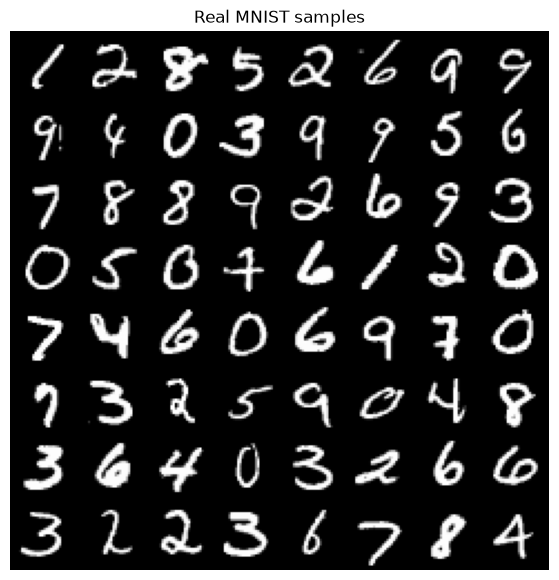

In [5]:
def show_image_grid(images, title=None, nrow=8):
    images = images.detach().cpu().clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")

## 4. Preprocessing for Flow Training

The logit transform maps pixel values from `(0, 1)` to the real line, where the Gaussian base distribution lives. Because the transform is invertible, we add its log-determinant to the flow log-determinant.

The small `logit_alpha` keeps values away from exactly `0` and `1`, where `logit` would become infinite.

In [6]:
def preprocess(images, alpha=logit_alpha):
    batch_size_seen = images.size(0)
    flat = images.view(batch_size_seen, -1)

    # Uniform dequantization turns discrete pixel bins into continuous values.
    dequantized = (flat * 255.0 + torch.rand_like(flat)) / 256.0
    constrained = alpha + (1 - 2 * alpha) * dequantized
    logits = torch.log(constrained) - torch.log1p(-constrained)

    log_det = math.log(1 - 2 * alpha) - torch.log(constrained) - torch.log1p(-constrained)
    log_det = log_det.sum(dim=1)
    return logits, log_det


def postprocess(logits):
    pixels = torch.sigmoid(logits)
    return pixels.view(-1, image_channels, image_size, image_size)

## 5. Affine Coupling Layers

A coupling layer leaves part of the vector unchanged and uses that part to scale and shift the rest. Because half the vector is copied through unchanged, the inverse is easy to compute and the log-determinant is just the sum of the scale values.

In [7]:
class CouplingNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, input_dim * 2),
        )

    def forward(self, x):
        shift, log_scale = self.net(x).chunk(2, dim=1)
        log_scale = torch.tanh(log_scale) * 2.0
        return shift, log_scale


class AffineCouplingLayer(nn.Module):
    def __init__(self, input_dim, hidden_dim, mask):
        super().__init__()
        self.register_buffer("mask", mask)
        self.network = CouplingNetwork(input_dim, hidden_dim)

    def forward(self, x):
        masked_x = x * self.mask
        shift, log_scale = self.network(masked_x)
        shift = shift * (1 - self.mask)
        log_scale = log_scale * (1 - self.mask)
        z = masked_x + (1 - self.mask) * (x * torch.exp(log_scale) + shift)
        log_det = log_scale.sum(dim=1)
        return z, log_det

    def inverse(self, z):
        masked_z = z * self.mask
        shift, log_scale = self.network(masked_z)
        shift = shift * (1 - self.mask)
        log_scale = log_scale * (1 - self.mask)
        x = masked_z + (1 - self.mask) * ((z - shift) * torch.exp(-log_scale))
        log_det = -log_scale.sum(dim=1)
        return x, log_det

## 6. Define the Normalizing Flow

The full flow stacks coupling layers with alternating masks. Alternating masks make sure every pixel can eventually be transformed by some layer.

In [8]:
class RealNVP(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=512, num_layers=8):
        super().__init__()
        layers = []
        base_mask = torch.arange(input_dim).float() % 2
        for layer_idx in range(num_layers):
            mask = base_mask if layer_idx % 2 == 0 else 1 - base_mask
            layers.append(AffineCouplingLayer(input_dim, hidden_dim, mask))
        self.layers = nn.ModuleList(layers)
        self.input_dim = input_dim

    def forward(self, x):
        log_det_total = torch.zeros(x.size(0), device=x.device)
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_total = log_det_total + log_det
        return z, log_det_total

    def inverse(self, z):
        log_det_total = torch.zeros(z.size(0), device=z.device)
        x = z
        for layer in reversed(self.layers):
            x, log_det = layer.inverse(x)
            log_det_total = log_det_total + log_det
        return x, log_det_total

    def log_prob(self, x):
        z, log_det = self.forward(x)
        log_base = -0.5 * (z.pow(2) + math.log(2 * math.pi)).sum(dim=1)
        return log_base + log_det

    def sample(self, num_samples):
        z = torch.randn(num_samples, self.input_dim, device=next(self.parameters()).device)
        x, _ = self.inverse(z)
        return x

## 7. Initialize Model and Optimizer

In [9]:
flow = RealNVP(image_dim, hidden_dim, num_coupling_layers).to(device)
optimizer = torch.optim.Adam(flow.parameters(), lr=learning_rate)

fixed_noise = torch.randn(64, image_dim, device=device)

print(flow)

RealNVP(
  (layers): ModuleList(
    (0-7): 8 x AffineCouplingLayer(
      (network): CouplingNetwork(
        (net): Sequential(
          (0): Linear(in_features=784, out_features=512, bias=True)
          (1): ReLU(inplace=True)
          (2): Linear(in_features=512, out_features=512, bias=True)
          (3): ReLU(inplace=True)
          (4): Linear(in_features=512, out_features=1568, bias=True)
        )
      )
    )
  )
)


## 8. Sampling and Checkpoint Helpers

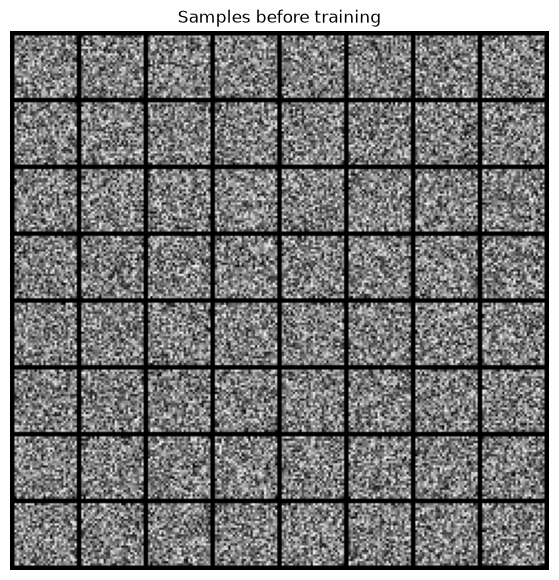

In [10]:
@torch.no_grad()
def sample_images(flow, noise=fixed_noise, title="Generated samples", save_path=None):
    flow.eval()
    logits, _ = flow.inverse(noise)
    images = postprocess(logits)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(images.cpu().clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(images, title=title, nrow=8)


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "flow_state_dict": flow.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": {
                "image_channels": image_channels,
                "image_size": image_size,
                "hidden_dim": hidden_dim,
                "num_coupling_layers": num_coupling_layers,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "logit_alpha": logit_alpha,
            },
        },
        checkpoint_path,
    )


sample_images(flow, title="Samples before training")

Before training, reverse samples are just random latent vectors pushed through an untrained invertible network.

## 9. Flow Training Step

Training maximizes exact log-likelihood. Equivalently, we minimize negative log-likelihood:

`-log p(x) = -log p(z) - log |det dz/dx|`

The preprocessing log-determinant is included because the logit transform is also part of the invertible map from pixels to latent space. For reporting, we also include the dequantization constant `image_dim * log(256)`, which converts the continuous density into the usual discrete-image likelihood lower bound.

In [11]:
def run_epoch(flow, data_loader, train=True):
    flow.train(train)
    total_nll = 0.0
    total_bits_per_dim = 0.0
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)
        x, preprocessing_log_det = preprocess(images)

        if train:
            optimizer.zero_grad(set_to_none=True)

        log_prob = flow.log_prob(x) + preprocessing_log_det
        nll = -log_prob.mean()

        if train:
            nll.backward()
            optimizer.step()

        batch_size_seen = images.size(0)
        total_nll += nll.item() * batch_size_seen
        bits_per_dim = nll.item() / (math.log(2) * image_dim)
        total_bits_per_dim += bits_per_dim * batch_size_seen
        total_images += batch_size_seen

    return {
        "nll": total_nll / total_images,
        "bits_per_dim": total_bits_per_dim / total_images,
    }


def train_one_epoch(epoch, flow, train_loader, test_loader):
    train_metrics = run_epoch(flow, train_loader, train=True)
    with torch.no_grad():
        test_metrics = run_epoch(flow, test_loader, train=False)

    return {
        "epoch": epoch,
        "train_nll": train_metrics["nll"],
        "train_bits_per_dim": train_metrics["bits_per_dim"],
        "test_nll": test_metrics["nll"],
        "test_bits_per_dim": test_metrics["bits_per_dim"],
    }

## 10. Train the Normalizing Flow

Run this cell to train. Lower negative log-likelihood and lower bits per dimension are better. Samples may improve slowly because this is a small fully connected flow over 784-dimensional images.

Epoch 001/020 | train NLL: 1943058.87 | train bits/dim: 3575.563 | test NLL: -2188.49 | test bits/dim: -4.027
Epoch 002/020 | train NLL: -2575.16 | train bits/dim: -4.739 | test NLL: -2770.63 | test bits/dim: -5.098
Epoch 003/020 | train NLL: -2814.06 | train bits/dim: -5.178 | test NLL: -2848.08 | test bits/dim: -5.241
Epoch 004/020 | train NLL: -2866.49 | train bits/dim: -5.275 | test NLL: -2885.45 | test bits/dim: -5.310
Epoch 005/020 | train NLL: -2899.03 | train bits/dim: -5.335 | test NLL: -2915.37 | test bits/dim: -5.365


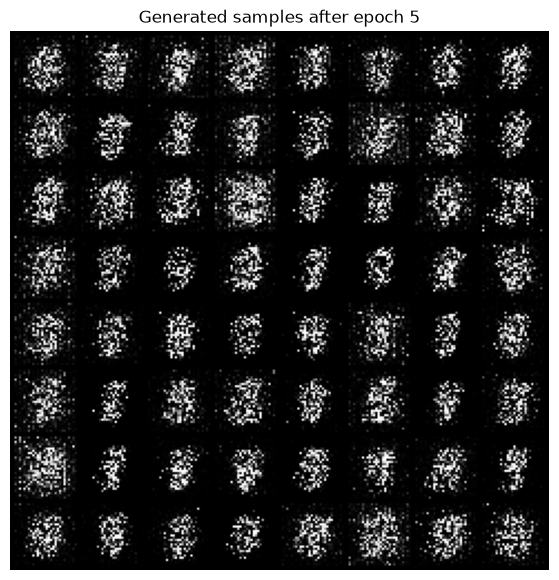

Epoch 006/020 | train NLL: -2927.63 | train bits/dim: -5.387 | test NLL: -2942.50 | test bits/dim: -5.415
Epoch 007/020 | train NLL: -2955.00 | train bits/dim: -5.438 | test NLL: -2968.66 | test bits/dim: -5.463
Epoch 008/020 | train NLL: -2976.21 | train bits/dim: -5.477 | test NLL: -2987.76 | test bits/dim: -5.498
Epoch 009/020 | train NLL: -2994.64 | train bits/dim: -5.511 | test NLL: -3004.48 | test bits/dim: -5.529
Epoch 010/020 | train NLL: -3009.43 | train bits/dim: -5.538 | test NLL: -3018.18 | test bits/dim: -5.554


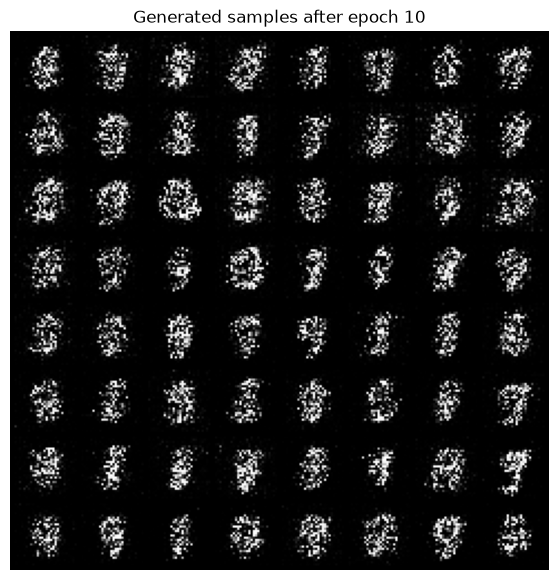

Epoch 011/020 | train NLL: -3021.97 | train bits/dim: -5.561 | test NLL: -3031.00 | test bits/dim: -5.578
Epoch 012/020 | train NLL: -3034.27 | train bits/dim: -5.584 | test NLL: -3041.74 | test bits/dim: -5.597
Epoch 013/020 | train NLL: -3045.42 | train bits/dim: -5.604 | test NLL: -3052.97 | test bits/dim: -5.618
Epoch 014/020 | train NLL: -3055.90 | train bits/dim: -5.623 | test NLL: -3062.78 | test bits/dim: -5.636
Epoch 015/020 | train NLL: -3065.43 | train bits/dim: -5.641 | test NLL: -3072.33 | test bits/dim: -5.654


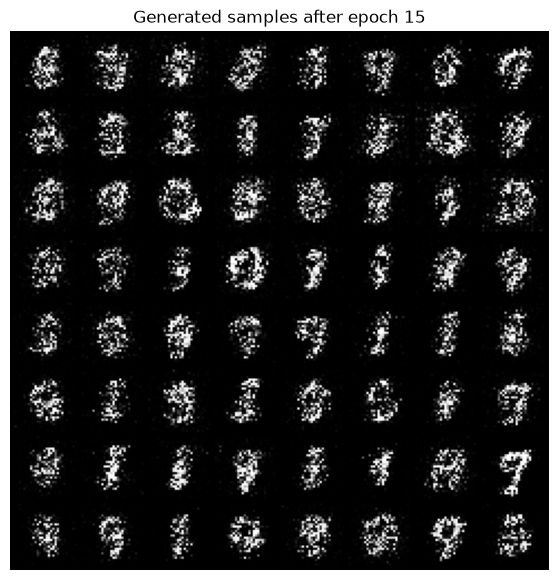

Epoch 016/020 | train NLL: -3074.35 | train bits/dim: -5.657 | test NLL: -3081.54 | test bits/dim: -5.671
Epoch 017/020 | train NLL: -3083.18 | train bits/dim: -5.674 | test NLL: -3090.35 | test bits/dim: -5.687
Epoch 018/020 | train NLL: -3091.37 | train bits/dim: -5.689 | test NLL: -3097.04 | test bits/dim: -5.699
Epoch 019/020 | train NLL: -3098.73 | train bits/dim: -5.702 | test NLL: -3104.71 | test bits/dim: -5.713
Epoch 020/020 | train NLL: -3105.98 | train bits/dim: -5.716 | test NLL: -3112.33 | test bits/dim: -5.727


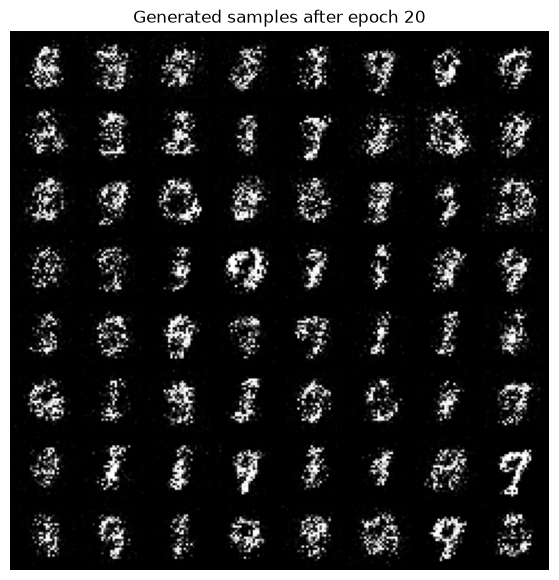

Saved latest checkpoint to: /home/nahuel/generative-networks/flows/outputs/mnist_normalizing_flow/mnist_normalizing_flow_checkpoint.pt


In [12]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, flow, train_loader, test_loader)
    history.append(metrics)

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"train NLL: {metrics['train_nll']:.2f} | "
        f"train bits/dim: {metrics['train_bits_per_dim']:.3f} | "
        f"test NLL: {metrics['test_nll']:.2f} | "
        f"test bits/dim: {metrics['test_bits_per_dim']:.3f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        sample_images(flow, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")

## 11. Plot Training Curves

Bits per dimension is the usual scale for image density models. It lets us compare likelihoods across image sizes.

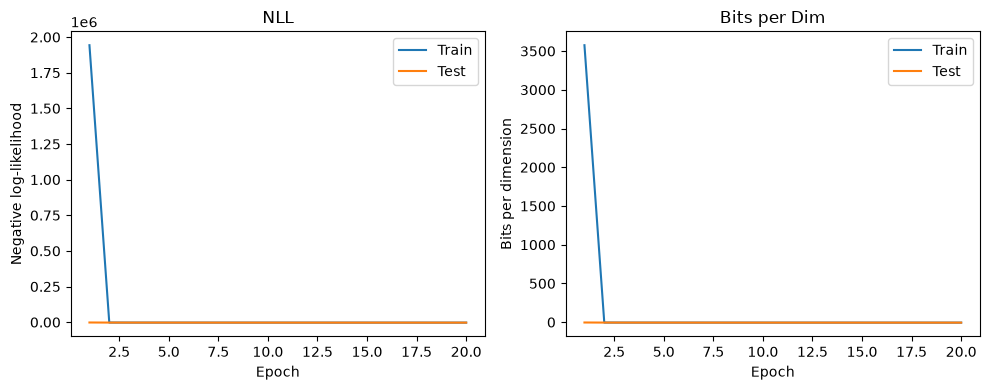

In [13]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_seen, [row["train_nll"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_nll"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.legend()
plt.title("NLL")

plt.subplot(1, 2, 2)
plt.plot(epochs_seen, [row["train_bits_per_dim"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_bits_per_dim"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Bits per dimension")
plt.legend()
plt.title("Bits per Dim")

plt.tight_layout()
plt.show()

## 12. Generate New Digits

To sample, draw `z` from the standard normal base distribution, invert the flow, then invert the logit transform with a sigmoid.

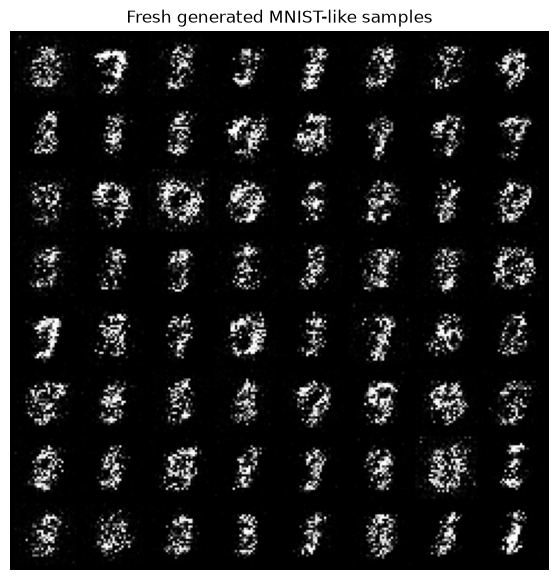

In [14]:
new_noise = torch.randn(64, image_dim, device=device)
sample_images(flow, noise=new_noise, title="Fresh generated MNIST-like samples")

## 13. Latent Space Interpolation

Because the model is invertible, we can interpolate in latent space and decode the path back to image space.

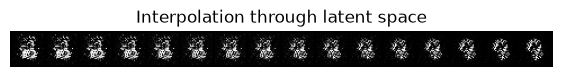

In [15]:
@torch.no_grad()
def interpolate(flow, steps=16):
    flow.eval()
    z_start = torch.randn(1, image_dim, device=device)
    z_end = torch.randn(1, image_dim, device=device)
    weights = torch.linspace(0, 1, steps, device=device).view(steps, 1)
    z = (1 - weights) * z_start + weights * z_end
    logits, _ = flow.inverse(z)
    images = postprocess(logits)
    show_image_grid(images, title="Interpolation through latent space", nrow=steps)


interpolate(flow)

## 14. Forward Flow Exact Log-Density

The forward pass maps an input from image/logit space to the Gaussian latent space and returns the change-of-variables log-determinant. For a real MNIST image, the preprocessing log-determinant is part of the exact density because dequantization and the logit transform are also invertible transforms applied before the flow.

`log p(image) = log p(z) + log |det dz/dx| + log |det d logit(pixel) / d pixel|`

For a generated noise sample, we draw latent Gaussian noise, decode it with the inverse flow, then push that decoded point through the forward flow again to evaluate its exact model density.


In [16]:
@torch.no_grad()
def forward_flow_density(flow, x, preprocessing_log_det=None):
    flow.eval()
    z, flow_log_det = flow.forward(x)
    base_log_density = -0.5 * (z.pow(2) + math.log(2 * math.pi)).sum(dim=1)
    log_density = base_log_density + flow_log_det

    if preprocessing_log_det is not None:
        log_density = log_density + preprocessing_log_det

    return {
        "z": z,
        "base_log_density": base_log_density,
        "flow_log_det": flow_log_det,
        "preprocessing_log_det": preprocessing_log_det,
        "log_density": log_density,
        "bits_per_dim": -log_density / (math.log(2) * image_dim),
    }


def print_density_report(name, density):
    preprocessing_log_det = density["preprocessing_log_det"]
    preprocessing_value = 0.0 if preprocessing_log_det is None else preprocessing_log_det.item()
    print(f"{name}")
    print(f"  base log p(z):        {density['base_log_density'].item():9.2f}")
    print(f"  forward log-det:      {density['flow_log_det'].item():9.2f}")
    print(f"  preprocessing log-det:{preprocessing_value:9.2f}")
    print(f"  exact log-density:    {density['log_density'].item():9.2f}")
    print(f"  bits/dim:             {density['bits_per_dim'].item():9.3f}")


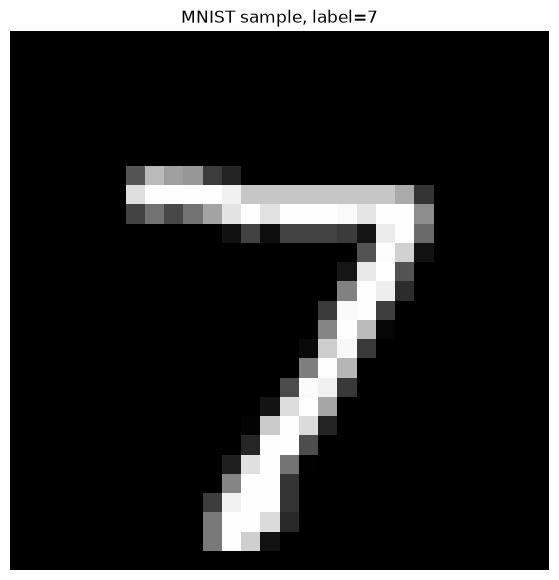

MNIST sample
  base log p(z):         -1072.05
  forward log-det:        -331.60
  preprocessing log-det:  4663.72
  exact log-density:      3260.06
  bits/dim:                -5.999


In [17]:
mnist_images, mnist_labels = next(iter(test_loader))
mnist_image = mnist_images[:1].to(device)
mnist_x, mnist_preprocessing_log_det = preprocess(mnist_image)
mnist_density = forward_flow_density(flow, mnist_x, mnist_preprocessing_log_det)

show_image_grid(mnist_image, title=f"MNIST sample, label={mnist_labels[0].item()}", nrow=1)
print_density_report("MNIST sample", mnist_density)


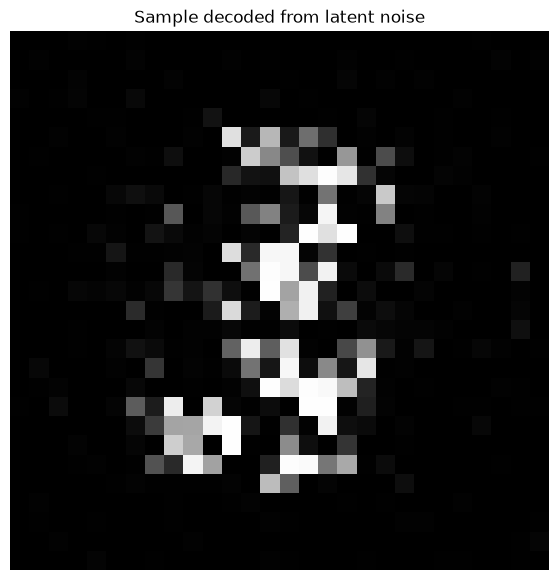

Noise sample decoded through inverse flow
  base log p(z):         -1122.64
  forward log-det:        -395.22
  preprocessing log-det:     0.00
  exact log-density:     -1517.86
  bits/dim:                 2.793
  inverse/forward roundtrip max error: 4.47e-06


In [18]:
noise_z = torch.randn(1, image_dim, device=device)
noise_logits, inverse_log_det = flow.inverse(noise_z)
noise_density = forward_flow_density(flow, noise_logits)
noise_image = postprocess(noise_logits)
roundtrip_error = (noise_density["z"] - noise_z).abs().max().item()

show_image_grid(noise_image, title="Sample decoded from latent noise", nrow=1)
print_density_report("Noise sample decoded through inverse flow", noise_density)
print(f"  inverse/forward roundtrip max error: {roundtrip_error:.2e}")


## 15. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.

In [34]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# flow.load_state_dict(checkpoint["flow_state_dict"])
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

## 16. Things to Try

- Train longer and inspect how likelihood and sample quality change.
- Increase `num_coupling_layers` to make the flow more expressive.
- Replace the alternating vector mask with image-aware checkerboard or channel masks.
- Add batch normalization or actnorm between coupling layers.
- Compare exact likelihood training here with the VAE objective and the flow matching objective.

## Troubleshooting

- If training becomes unstable, lower `learning_rate` or reduce the log-scale multiplier in `CouplingNetwork`.
- If samples look noisy, train longer or add more coupling layers.
- If you run out of GPU memory, lower `batch_size` or `hidden_dim`.